<a href="https://colab.research.google.com/github/Mahak-Rathore/Pharmacy-Drug-Management-System-DBMS-Project/blob/main/Early_Flood_Level_Prediction_using_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Early Flood Level Prediction using LSTM

## What is this project?

Floods can happen when the water level in rivers increases continuously. If we can predict the water level in advance, we can give an early warning and help people prepare for possible floods.

### In this project:
* We collect historical water-level data.
* We prepare the data for training.
* We train an LSTM model.
* We predict the next water level.
* We display a graph of actual and predicted water levels.

### Technologies used:
* Python
* Google Colab
* Pandas
* NumPy
* Matplotlib
* Scikit-learn
* TensorFlow / Keras (LSTM)

###1. Import Required Libraries

In this step, we import the required Python libraries for data processing, visualization and building the LSTM model.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

print("Libraries imported successfully!")

Libraries imported successfully!


###2. Dataset Creation

In this step, we generate sample water-level data for 100 days with hourly readings. This dataset is used to train and test our LSTM model.

In [ ]:
np.random.seed(42)

days = 100
hours = days * 24

time = np.arange(hours)

# Generate sample water level readings
water_level = (
    2
    + 0.5 * np.sin(time / 24)
    + 0.3 * np.sin(time / 100)
    + 0.002 * time
    + np.random.normal(0, 0.08, hours)
)

# Create DataFrame
df = pd.DataFrame({
    'Water_Level': water_level
})

print(df.head())
print("Total records:", len(df))

   Water_Level
0     2.039737
1     2.014766
2     2.103433
3     2.199178
4     2.084213
Total records: 2400


###3. Dataset Visualization
In this step, we visualize the historical water-level data using a line graph to understand how water levels change over time.

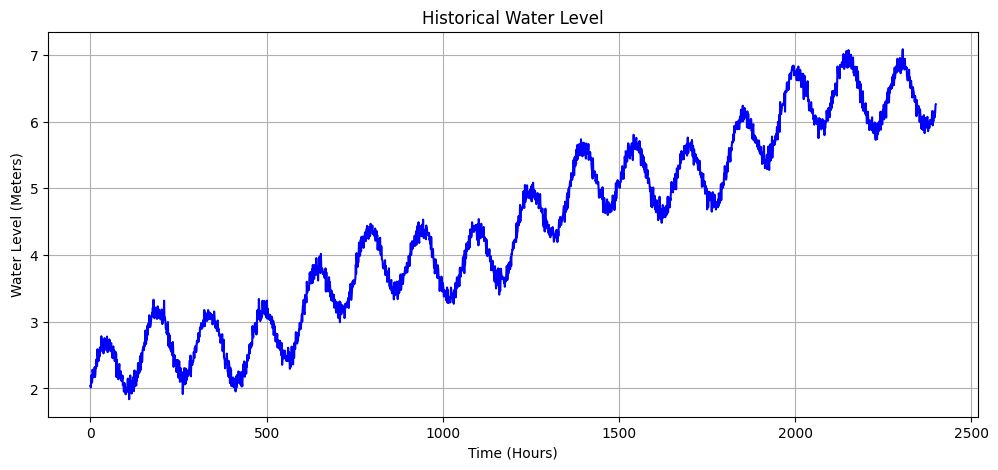

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(df['Water_Level'], color='blue')

plt.title("Historical Water Level")
plt.xlabel("Time (Hours)")
plt.ylabel("Water Level (Meters)")

plt.grid(True)
plt.show()

###4. Data Preprocessing
In this step, we divide the dataset into training and testing data. We also normalize the values between 0 and 1 to make model training easier.

In [ ]:
# Convert data into NumPy array
data = df['Water_Level'].values.reshape(-1, 1)

# Split data into training and testing
split = int(len(data) * 0.8)

train_data = data[:split]
test_data = data[split:]

# Normalize the data
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

print("Training data:", len(train_scaled))
print("Testing data:", len(test_scaled))

Training data: 1920
Testing data: 480


###5. Sequence Creation
In this step, we use the previous 24 hours of water-level readings to predict the next hour's water level. This data format is required for training the LSTM model.

In [ ]:
def create_sequences(data, time_steps=24):

    X = []
    y = []

    for i in range(time_steps, len(data)):

        X.append(data[i-time_steps:i, 0])
        y.append(data[i, 0])

    return np.array(X), np.array(y)


# Create training sequences
X_train, y_train = create_sequences(train_scaled)

# Create testing sequences
combined_data = np.concatenate((train_scaled[-24:], test_scaled))

X_test, y_test = create_sequences(combined_data)

# Reshape for LSTM
X_train = X_train.reshape(X_train.shape[0], 24, 1)
X_test = X_test.reshape(X_test.shape[0], 24, 1)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1896, 24, 1)
X_test shape: (480, 24, 1)


###6. Building the LSTM Model
In this step, we create an LSTM model with two LSTM layers, a Dropout layer and a Dense layer. The model learns patterns from previous water-level readings.

In [ ]:
model = Sequential()

# First LSTM layer
model.add(LSTM(
    50,
    activation='tanh',
    return_sequences=True,
    input_shape=(24, 1)
))

# Dropout layer
model.add(Dropout(0.2))

# Second LSTM layer
model.add(LSTM(50, activation='tanh'))

# Output layer
model.add(Dense(1))

# Compile model
model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

###7. Training the LSTM Model
In this step, we train the LSTM model using the training dataset. The model learns the relationship between previous water-level readings and future water levels.

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    shuffle=False
)

print("Model training completed!")

Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - loss: 0.0064 - val_loss: 0.0016
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0053 - val_loss: 0.0022
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0047 - val_loss: 0.0015
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0021 - val_loss: 0.0011
Epoch 5/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0014 - val_loss: 9.2905e-04
Epoch 6/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0014 - val_loss: 0.0010
Epoch 7/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0014 - val_loss: 8.5592e-04
Epoch 8/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0012 - val_loss: 7.8787e-04
Epoch 9/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0011 - val_loss: 7.7261e-04
Epoch 10/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0011 - val_loss: 0.0011
Model training completed!


###8. Water Level Prediction
In this step, we use the trained LSTM model to predict water levels from the testing dataset. The predicted values are converted back into meters.

In [ ]:
# Make predictions
predictions = model.predict(X_test)

# Convert predictions back to original scale
predicted_levels = scaler.inverse_transform(predictions)

# Convert actual values back to original scale
actual_levels = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

print("First 10 predicted water levels:")
print(predicted_levels[:10])

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
First 10 predicted water levels:
[[5.523628 ]
 [5.508547 ]
 [5.5074983]
 [5.503488 ]
 [5.5070376]
 [5.5265255]
 [5.536599 ]
 [5.532332 ]
 [5.533011 ]
 [5.544806 ]]


###9. Actual vs Predicted Water Level
In this step, we compare the actual water-level readings with the predicted readings using a line graph. This helps us understand the prediction performance of the model.

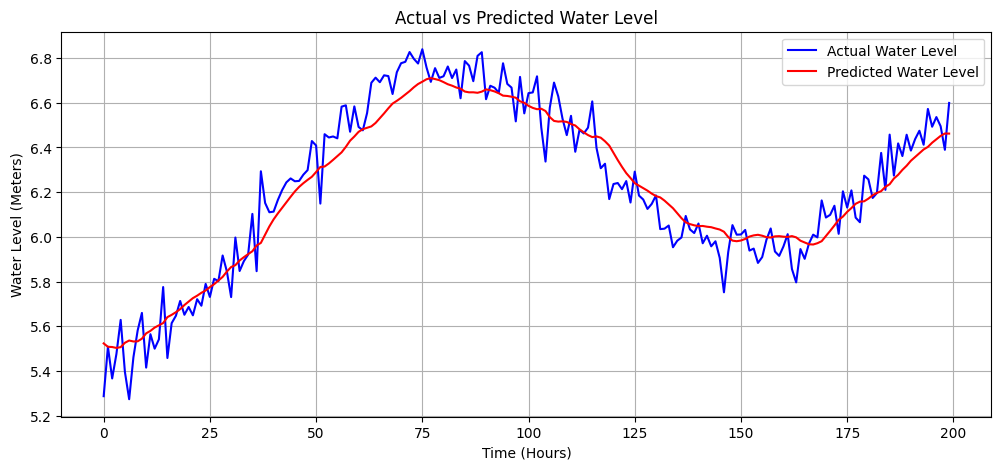

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    actual_levels[:200],
    label='Actual Water Level',
    color='blue'
)

plt.plot(
    predicted_levels[:200],
    label='Predicted Water Level',
    color='red'
)

plt.title("Actual vs Predicted Water Level")
plt.xlabel("Time (Hours)")
plt.ylabel("Water Level (Meters)")

plt.legend()
plt.grid(True)
plt.show()

###10. Model Evaluation
In this step, we calculate MAE, MSE and RMSE to measure the difference between actual and predicted water levels. Lower error values generally indicate better prediction performance.**bold text**

In [ ]:
mae = mean_absolute_error(
    actual_levels,
    predicted_levels
)

mse = mean_squared_error(
    actual_levels,
    predicted_levels
)

rmse = np.sqrt(mse)

print("Mean Absolute Error:", round(mae, 4))
print("Mean Squared Error:", round(mse, 4))
print("Root Mean Squared Error:", round(rmse, 4))

Mean Absolute Error: 0.0901
Mean Squared Error: 0.0123
Root Mean Squared Error: 0.1109


###11. Predicting the Next Hour's Water Level
In this step, we use the latest 24 hours of water-level readings to predict the water level for the next hour.

In [ ]:
# Get the latest 24 readings
last_24_hours = data[-24:]

# Normalize the readings
last_24_scaled = scaler.transform(last_24_hours)

# Reshape input for LSTM
input_data = last_24_scaled.reshape(1, 24, 1)

# Predict next hour
next_prediction = model.predict(input_data, verbose=0)

# Convert back to original scale
next_water_level = scaler.inverse_transform(
    next_prediction
)[0][0]

print("Predicted Water Level for Next Hour:",
      round(next_water_level, 2), "meters")

Predicted Water Level for Next Hour: 6.16 meters


###12. Early Flood Warning

In this step, we compare the predicted water level with a predefined warning threshold of 3 meters. If the predicted level reaches or exceeds this threshold, the system displays a warning message.

In [ ]:
warning_level = 3.0

print("Predicted Water Level:",
      round(next_water_level, 2), "meters")

print("Warning Level:", warning_level, "meters")

if next_water_level >= warning_level:

    print("WARNING: Water level is high!")
    print("Possible flood risk. Take precautionary measures.")

else:

    print("NORMAL: Water level is below warning level.")

Predicted Water Level: 6.16 meters
Warning Level: 3.0 meters
Possible flood risk. Take precautionary measures.


### Project conclusion
This project, Early Flood Level Prediction using LSTM, uses a deep learning technique called Long Short-Term Memory to predict future water levels based on previous readings. The model learns patterns from historical data and predicts the water level for the next hour. The predicted water level is compared with a predefined warning threshold to identify possible high-water-level conditions. This project demonstrates how deep learning can help in early flood monitoring.